# Exploring the Amazon Berkeley Objects Dataset

This notebook inspects the ABO product listings and catalog images before building
the CLIP embedding pipeline.

The main relationship we need to understand is:

product listing
    → main_image_id
    → image metadata
    → local image path

In [1]:
from pathlib import Path 
import csv 
import gzip 
import json 

In [2]:
current_directory = Path.cwd() 

if current_directory.name == "notebooks": 
    project_root = current_directory.parent 
else: 
    project_root = current_directory 

print("Current directory:", current_directory) 
print("Project root:", project_root) 

Current directory: /Users/aob/AOB/CS/Projects/clip-semantic-search/notebooks
Project root: /Users/aob/AOB/CS/Projects/clip-semantic-search


In [3]:
abo_root = project_root / "data" / "ABO" 

listings_root = (
    abo_root 
    / "abo-listings" 
    / "listings"
)

images_root = (
    abo_root 
    / "abo-images-small" 
    / "images" 
)

image_metadata_path = (
    images_root 
    / "metadata" 
    / "images.csv.gz" 
)

listings_metadata_root = listings_root / "metadata" 
small_images_root = images_root / "small" 

In [4]:
print("ABO root:", abo_root) 
print("Listings root:", listings_root) 
print("Listings metadata:", listings_metadata_root) 
print("Image metadata:", image_metadata_path)
print("Small images:", small_images_root) 

ABO root: /Users/aob/AOB/CS/Projects/clip-semantic-search/data/ABO
Listings root: /Users/aob/AOB/CS/Projects/clip-semantic-search/data/ABO/abo-listings/listings
Listings metadata: /Users/aob/AOB/CS/Projects/clip-semantic-search/data/ABO/abo-listings/listings/metadata
Image metadata: /Users/aob/AOB/CS/Projects/clip-semantic-search/data/ABO/abo-images-small/images/metadata/images.csv.gz
Small images: /Users/aob/AOB/CS/Projects/clip-semantic-search/data/ABO/abo-images-small/images/small


In [5]:
paths_to_check = {
    "ABO root": abo_root, 
    "Listings root": listings_root, 
    "Listings metadata": listings_metadata_root, 
    "Image metadata": image_metadata_path, 
    "Small images": small_images_root, 
}

for name, path in paths_to_check.items(): 
    print(f"{name}: {'OK' if path.exists() else 'MISSING'}")

ABO root: OK
Listings root: OK
Listings metadata: OK
Image metadata: OK
Small images: OK


### Inspect the iamge metadata header `images.csv.gz`

In [6]:
with gzip.open(image_metadata_path, mode='rt', encoding='utf-8') as file: 
    first_line = file.readline().strip() 

print(first_line)

image_id,height,width,path


In [7]:
with gzip.open(image_metadata_path, mode='rt', encoding='utf-8') as file: 
    reader = csv.DictReader(file) 

    for index, row in enumerate(reader): 
        print(row) 

        if index == 4: 
            break 

{'image_id': '010-mllS7JL', 'height': '106', 'width': '106', 'path': '14/14fe8812.jpg'}
{'image_id': '01dkn0Gyx0L', 'height': '122', 'width': '122', 'path': 'da/daab0cad.jpg'}
{'image_id': '01sUPg0387L', 'height': '111', 'width': '111', 'path': 'd2/d2daaae9.jpg'}
{'image_id': '1168jc-5r1L', 'height': '186', 'width': '186', 'path': '3a/3a4e88e6.jpg'}
{'image_id': '11RUV5Fs65L', 'height': '30', 'width': '500', 'path': 'd9/d91ab9cf.jpg'}


In [8]:
# Count image metadata rows 
image_metadata_count = 0 

with gzip.open(image_metadata_path, mode='rt', encoding='utf-8') as file: 
    reader = csv.DictReader(file) 

    for row in reader: 
        image_metadata_count += 1 

print("Image metadata records:", image_metadata_count) 

Image metadata records: 398212


In [9]:
checked_images = 0 
existing_images = 0 
missing_images = [] 

with gzip.open(image_metadata_path, mode='rt', encoding='utf-8') as file: 
    reader = csv.DictReader(file) 

    for row in reader: 
        relative_image_path = Path(row["path"]) 
        local_image_path = small_images_root / relative_image_path 

        checked_images += 1 

        if local_image_path.is_file(): 
            existing_images += 1 
        else: 
            missing_images.append(str(local_image_path)) 

print("Checked image records:", checked_images) 
print("Existing local iamges:", existing_images) 
print("Missing local images:", len(missing_images)) 

Checked image records: 398212
Existing local iamges: 398212
Missing local images: 0


In [10]:
for path in missing_images[:10]: 
    print(path)

In [11]:
from PIL import Image 
import matplotlib.pyplot as plt 

In [12]:
first_image_path = None 

with gzip.open(image_metadata_path, mode='rt', encoding='utf-8') as file: 
    reader = csv.DictReader(file) 

    for row in reader: 
        candidate_path = small_images_root / row["path"] 

        if candidate_path.is_file(): 
            first_image_path = candidate_path 
            first_image_record = row   
            break 

if first_image_path is None: 
    raise FileNotFoundError("No valid local ABO image was found.") 

print("Image metadata:", first_image_record) 
print("Local image path:", first_image_path) 

Image metadata: {'image_id': '010-mllS7JL', 'height': '106', 'width': '106', 'path': '14/14fe8812.jpg'}
Local image path: /Users/aob/AOB/CS/Projects/clip-semantic-search/data/ABO/abo-images-small/images/small/14/14fe8812.jpg


Image mode: RGB
Image size: (106, 106)


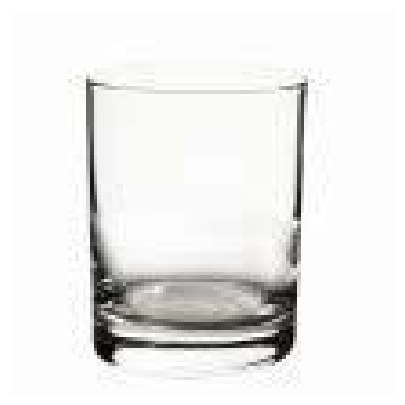

In [13]:
image = Image.open(first_image_path).convert("RGB") 

print("Image mode:", image.mode) 
print("Image size:", image.size) 

plt.figure(figsize=(5,5)) 
plt.imshow(image) 
plt.axis("off") 
plt.show() 

## Inspecting ABO Product Listings

The product metadata is stored as 16 gzip-compressed JSON Lines files.

Each line represents one product listing. We will first inspect the files and
one product record before building the image-to-product join.

In [14]:
listing_files = sorted(
    listings_metadata_root.glob("listings_*.json.gz")
)

print("Listing metadata files:", len(listing_files)) 

for path in listing_files: 
    print(path.name) 

Listing metadata files: 16
listings_0.json.gz
listings_1.json.gz
listings_2.json.gz
listings_3.json.gz
listings_4.json.gz
listings_5.json.gz
listings_6.json.gz
listings_7.json.gz
listings_8.json.gz
listings_9.json.gz
listings_a.json.gz
listings_b.json.gz
listings_c.json.gz
listings_d.json.gz
listings_e.json.gz
listings_f.json.gz


In [15]:
first_listing = None 

with gzip.open(listing_files[0], mode='rt', encoding='utf-8') as file: 
    first_line = file.readline().strip() 

first_listing = json.loads(first_line) 
print(type(first_listing))
print(first_listing.keys())

<class 'dict'>
dict_keys(['brand', 'bullet_point', 'color', 'item_id', 'item_name', 'model_name', 'model_number', 'model_year', 'product_type', 'style', 'main_image_id', 'other_image_id', 'item_keywords', 'country', 'marketplace', 'domain_name', 'node'])


In [16]:
fields_to_inspect = [
    "item_id",
    "domain_name",
    "item_name",
    "main_image_id",
    "other_image_id",
    "product_type",
    "brand",
    "color",
    "material",
    "style",
]

for field in fields_to_inspect:
    print(f"\n{field}:")
    print(first_listing.get(field))


item_id:
B06X9STHNG

domain_name:
amazon.nl

item_name:
[{'language_tag': 'nl_NL', 'value': 'Amazon-merk - vinden. Dames Leder Gesloten Teen Hakken,Veelkleurig Vrouw Blauw,5 UK'}]

main_image_id:
81iZlv3bjpL

other_image_id:
['91mIRxgziUL', '91eqBkW06wL', 'A1BHZSKNbkL']

product_type:
[{'value': 'SHOES'}]

brand:
[{'language_tag': 'nl_NL', 'value': 'find.'}]

color:
[{'language_tag': 'nl_NL', 'value': 'Veelkleurig Vrouw Blauw'}]

material:
None

style:
[{'language_tag': 'nl_NL', 'value': 'Gesloten-teen pompen'}]


In [17]:
item_name = first_listing.get("item_name") 

print("item_name type:", type(item_name))
print("item_name value:", item_name)

item_name type: <class 'list'>
item_name value: [{'language_tag': 'nl_NL', 'value': 'Amazon-merk - vinden. Dames Leder Gesloten Teen Hakken,Veelkleurig Vrouw Blauw,5 UK'}]


In [18]:
listing_count = 0 

for listing_file in listing_files: 
    with gzip.open(listing_file, mode='rt', encoding='utf-8') as file: 
        for line in file: 
            if line.strip(): 
                listing_count += 1 

print("Product listing records:", listing_count) 

Product listing records: 147702


In [19]:
listings_with_main_image = 0 
listings_without_main_image = 0 

for listing_file in listing_files: 
    with gzip.open(listing_file, mode='rt', encoding='utf-8') as file: 
        for line in file: 
            if not line.strip(): 
                continue
            listing = json.loads(line) 

            if listing.get("main_image_id"): 
                listings_with_main_image += 1 
            else: 
                listings_without_main_image += 1

print("Listings with main image:", listings_with_main_image)
print("Listings without main image", listings_without_main_image) 

Listings with main image: 147127
Listings without main image 575


In [20]:
# Image lookup directory 
image_metadata_by_id = {} 

with gzip.open(image_metadata_path, mode='rt', encoding='utf-8') as file: 
    reader = csv.DictReader(file) 

    for row in reader: 
        image_metadata_by_id[row['image_id']] = row 

print("Image metadata lookup entries:", len(image_metadata_by_id)) 

Image metadata lookup entries: 398212


In [21]:
main_image_id = first_listing.get("main_image_id") 

print("Main image ID:", main_image_id) 

image_record = image_metadata_by_id.get(main_image_id) 

print("Matching image record:", image_record) 

Main image ID: 81iZlv3bjpL
Matching image record: {'image_id': '81iZlv3bjpL', 'height': '2560', 'width': '1969', 'path': '8c/8ccb5859.jpg'}


In [22]:
if image_record is not None: 
    relative_path = Path(image_record["path"]) 
    local_path = small_images_root / relative_path 

    print("Local image path:", local_path)
    print("File exists:", local_path.is_file())

Local image path: /Users/aob/AOB/CS/Projects/clip-semantic-search/data/ABO/abo-images-small/images/small/8c/8ccb5859.jpg
File exists: True


## Building Clean Product Records

ABO metadata fields such as `item_name`, `brand`, `color`, and `style`
are lists of language-tagged dictionaries. We will extract an English value
when available and otherwise use the first available value.

In [23]:
def extract_text_value(values, preferred_language='en_US'): 
    if not values: 
        return None 

    if isinstance(values, str): 
        return values 

    if not isinstance(values, list): 
        return None 

    for value_entry in values: 
        if not isinstance(value_entry, dict): 
            continue 

        if value_entry.get("language_tag") == preferred_language: 
            value = value_entry.get("value") 

            if value: 
                return str(value).strip() 

    for value_entry in values: 
        if not isinstance(value_entry, dict): 
            continue 

        value = value_entry.get("value") 

        if value: 
            return str(value).strip() 

    return None 

In [24]:
print(extract_text_value(first_listing.get("item_name")))
print(extract_text_value(first_listing.get("brand")))
print(extract_text_value(first_listing.get("color")))
print(extract_text_value(first_listing.get("style")))

Amazon-merk - vinden. Dames Leder Gesloten Teen Hakken,Veelkleurig Vrouw Blauw,5 UK
find.
Veelkleurig Vrouw Blauw
Gesloten-teen pompen


In [25]:
def extract_product_type(values): 
    if not values: 
        return None 

    if isinstance(values, str): 
        return values.strip() 

    if not isinstance(values, list): 
        return None 

    for value_entry in values: 
        if not isinstance(value_entry, dict): 
            continue 

        value = value_entry.get("value")

        if value: 
            return str(value).strip() 

    return None 

In [26]:
print(extract_product_type(first_listing.get("product_type")))

SHOES


In [27]:
def build_product_record(listing, image_metadata_by_id, small_images_root): 
    main_image_id = listing.get("main_image_id") 

    if not main_image_id: 
        return None 

    image_record = image_metadata_by_id.get(main_image_id)

    if image_record is None: 
        return None 

    image_path = small_images_root / image_record["path"]

    if not image_path.is_file(): 
        return None 

    return {
        "item_id": listing.get("item_id"), 
        "domain_name": listing.get("domain_name"), 
        "image_id": main_image_id, 
        "image_path": str(image_path), 
        "title": extract_text_value(listing.get("item_name")), 
        "product_type": extract_product_type(listing.get("product_type")),
        "brand": extract_text_value(listing.get("brand")), 
        "color": extract_text_value(listing.get("color")), 
        "style": extract_text_value(listing.get("style")), 
    }

In [28]:
test_record = build_product_record(
    first_listing,
    image_metadata_by_id,
    small_images_root,
)

print(test_record)

{'item_id': 'B06X9STHNG', 'domain_name': 'amazon.nl', 'image_id': '81iZlv3bjpL', 'image_path': '/Users/aob/AOB/CS/Projects/clip-semantic-search/data/ABO/abo-images-small/images/small/8c/8ccb5859.jpg', 'title': 'Amazon-merk - vinden. Dames Leder Gesloten Teen Hakken,Veelkleurig Vrouw Blauw,5 UK', 'product_type': 'SHOES', 'brand': 'find.', 'color': 'Veelkleurig Vrouw Blauw', 'style': 'Gesloten-teen pompen'}


In [29]:
clean_records = [] 

skipped_without_main_image = 0 
skipped_without_image_metadata = 0 
skipped_missing_local_file = 0 

for listing_file in listing_files: 
    with gzip.open(listing_file, mode='rt', encoding='utf-8') as file: 
        for line in file: 
            if not line.strip(): 
                continue 

            listing = json.loads(line) 
            main_image_id = listing.get("main_image_id") 

            if not main_image_id: 
                skipped_without_main_image += 1 
                continue 

            image_record = image_metadata_by_id.get(main_image_id) 

            if image_record is None: 
                skipped_without_image_metadata += 1 
                continue 

            image_record = image_metadata_by_id.get(main_image_id) 

            if image_record is None: 
                skipped_without_image_metadata += 1 
                continue 

            image_path = small_images_root / image_record['path'] 

            if not image_path.is_file(): 
                skipped_missing_local_file += 1
                continue 

            clean_records.append(
                {
                    "item_id": listing.get("item_id"), 
                    "domain_name": listing.get("domain_name"), 
                    "image_id": main_image_id, 
                    "image_path": str(image_path), 
                    "title": extract_text_value(listing.get("item_name")), 
                    "product_type": extract_product_type(listing.get("product_type")), 
                    "brand": extract_text_value(listing.get("brand")), 
                    "color": extract_text_value(listing.get("color")), 
                    "style": extract_text_value(listing.get("style")), 
                }
            )

print("Clean records:", len(clean_records))
print("Skipped without main image:", skipped_without_main_image) 
print("Skipped without image metadata:", skipped_without_image_metadata) 
print("Skipped missing local files:", skipped_missing_local_file) 

Clean records: 147127
Skipped without main image: 575
Skipped without image metadata: 0
Skipped missing local files: 0


In [30]:
clean_records[0] 

{'item_id': 'B06X9STHNG',
 'domain_name': 'amazon.nl',
 'image_id': '81iZlv3bjpL',
 'image_path': '/Users/aob/AOB/CS/Projects/clip-semantic-search/data/ABO/abo-images-small/images/small/8c/8ccb5859.jpg',
 'title': 'Amazon-merk - vinden. Dames Leder Gesloten Teen Hakken,Veelkleurig Vrouw Blauw,5 UK',
 'product_type': 'SHOES',
 'brand': 'find.',
 'color': 'Veelkleurig Vrouw Blauw',
 'style': 'Gesloten-teen pompen'}

In [31]:
clean_records[10]

{'item_id': 'B07J2BHRNW',
 'domain_name': 'amazon.fr',
 'image_id': '71QExDBDozL',
 'image_path': '/Users/aob/AOB/CS/Projects/clip-semantic-search/data/ABO/abo-images-small/images/small/39/39e34e19.jpg',
 'title': 'Richter Kinderschuhe Bios, Mules Mixte Enfant Beige (Taupe Taupe) 42 EU',
 'product_type': 'SHOES',
 'brand': 'find.',
 'color': 'Beige Taupe Taupe',
 'style': 'Mocassins'}

In [32]:
clean_records[1000]

{'item_id': 'B07TC4ZFTW',
 'domain_name': 'amazon.in',
 'image_id': '81PBgc5VM0L',
 'image_path': '/Users/aob/AOB/CS/Projects/clip-semantic-search/data/ABO/abo-images-small/images/small/33/33a35957.jpg',
 'title': 'Amazon Brand - Solimo Designer Sea Seen 3D Printed Hard Back Case Mobile Cover for Samsung Galaxy S5 i9600',
 'product_type': 'CELLULAR_PHONE_CASE',
 'brand': 'Amazon Brand - Solimo',
 'color': 'Others',
 'style': None}

In [33]:
for record in clean_records[:5]: 
    print(record) 
    print() 

{'item_id': 'B06X9STHNG', 'domain_name': 'amazon.nl', 'image_id': '81iZlv3bjpL', 'image_path': '/Users/aob/AOB/CS/Projects/clip-semantic-search/data/ABO/abo-images-small/images/small/8c/8ccb5859.jpg', 'title': 'Amazon-merk - vinden. Dames Leder Gesloten Teen Hakken,Veelkleurig Vrouw Blauw,5 UK', 'product_type': 'SHOES', 'brand': 'find.', 'color': 'Veelkleurig Vrouw Blauw', 'style': 'Gesloten-teen pompen'}

{'item_id': 'B07P8ML82R', 'domain_name': 'amazon.com.mx', 'image_id': '619y9YG9cnL', 'image_path': '/Users/aob/AOB/CS/Projects/clip-semantic-search/data/ABO/abo-images-small/images/small/9f/9f76d27b.jpg', 'title': '22" Bottom Mount Drawer Slides, White Powder Coat, 10 Pairs', 'product_type': 'HARDWARE', 'brand': 'AmazonBasics', 'color': 'White Powder Coat', 'style': '10 pares'}

{'item_id': 'B07H9GMYXS', 'domain_name': 'amazon.ae', 'image_id': '81NP7qh2L6L', 'image_path': '/Users/aob/AOB/CS/Projects/clip-semantic-search/data/ABO/abo-images-small/images/small/66/665cc994.jpg', 'title'

In [34]:
sample_record = clean_records[0] 

print(Path(sample_record["image_path"]).is_file())

True


In [35]:
metadata_fields = [
    "title", 
    "product_type", 
    "brand", 
    "color", 
    "style"
]

for field in metadata_fields: 
    missing_count = sum(record[field] is None for record in clean_records)

    available_count = len(clean_records) - missing_count

    print(
        f"{field}: " 
        f"{available_count} available, " 
        f"{missing_count} missing" 
    )

title: 147127 available, 0 missing
product_type: 147127 available, 0 missing
brand: 147068 available, 59 missing
color: 115799 available, 31328 missing
style: 43117 available, 104010 missing


In [36]:
from collections import Counter 

product_type_counts = Counter(
    record['product_type']
    for record in clean_records
)

print("Unique product types:", len(product_type_counts))

for product_type, count in product_type_counts.most_common(30):
    print(f"{product_type}: {count}")

Unique product types: 573
CELLULAR_PHONE_CASE: 64825
SHOES: 12964
GROCERY: 6509
HOME: 5247
HOME_BED_AND_BATH: 3078
HOME_FURNITURE_AND_DECOR: 2195
CHAIR: 2099
BOOT: 2009
SANDAL: 1845
FINERING: 1540
HEALTH_PERSONAL_CARE: 1409
FINENECKLACEBRACELETANKLET: 1377
ACCESSORY: 1317
SOFA: 1198
OFFICE_PRODUCTS: 1152
FINEEARRING: 1137
PET_SUPPLIES: 1062
TABLE: 936
SPORTING_GOODS: 920
HARDWARE_HANDLE: 860
RUG: 817
HANDBAG: 773
LIGHT_BULB: 756
KITCHEN: 706
EARRING: 645
OUTDOOR_LIVING: 631
WALL_ART: 598
JANITORIAL_SUPPLY: 579
HAT: 545
LIGHT_FIXTURE: 544


In [37]:
image_id_counts = Counter(
    record["image_id"]
    for record in clean_records
)

duplicate_image_ids = {
    image_id: count 
    for image_id, count in image_id_counts.items() 
    if count > 1
}

print("Unique image IDs:", len(image_id_counts))
print("Duplicate image IDs:", len(duplicate_image_ids))

Unique image IDs: 123511
Duplicate image IDs: 11244


In [38]:
deduplicated_records = [] 
seen_image_ids = set() 

for record in clean_records: 
    image_id = record['image_id']

    if image_id in seen_image_ids: 
        continue

    seen_image_ids.add(image_id) 
    deduplicated_records.append(record) 

print("Records before deduplication:", len(clean_records))
print("Records after deduplication:", len(deduplicated_records)) 

Records before deduplication: 147127
Records after deduplication: 123511


## Selecting a Balanced ABO Subset

The ABO dataset contains many product types with highly uneven frequencies.
To prevent common categories such as phone cases from dominating the search
results, we select a deterministic subset containing 100 images from each of
10 product categories.

In [39]:
selected_product_types = [
    "CELLULAR_PHONE_CASE",
    "SHOES",
    "GROCERY",
    "HOME",
    "HOME_BED_AND_BATH",
    "HOME_FURNITURE_AND_DECOR",
    "CHAIR",
    "BOOT",
    "SANDAL",
    "HANDBAG",
]

records_per_category = 100 

print("Categories:", len(selected_product_types))
print("Records per category:", records_per_category)
print("Expected subset size:", len(selected_product_types) * records_per_category)

Categories: 10
Records per category: 100
Expected subset size: 1000


In [40]:
from collections import defaultdict 

records_by_product_type = defaultdict(list) 

for record in deduplicated_records: 
    product_type = record['product_type'] 

    if product_type in selected_product_types: 
        records_by_product_type[product_type].append(record)

In [41]:
for product_type in selected_product_types:
    available_count = len(records_by_product_type[product_type])

    print(
        f"{product_type}: " 
        f"{available_count} available"
    )

    if available_count < records_per_category: 
        raise ValueError(
            f"{product_type} has only {available_count} records, "
            f"but {records_per_category} are required."
        )

CELLULAR_PHONE_CASE: 64406 available
SHOES: 5599 available
GROCERY: 5098 available
HOME: 3322 available
HOME_BED_AND_BATH: 1801 available
HOME_FURNITURE_AND_DECOR: 1749 available
CHAIR: 1878 available
BOOT: 542 available
SANDAL: 471 available
HANDBAG: 759 available


In [42]:
subset_records = [] 

for product_type in selected_product_types: 
    category_records = records_by_product_type[product_type]

    category_records_sorted = sorted(
        category_records, 
        key=lambda record: record['image_id'], 
    )

    selected_category_records = category_records_sorted[:records_per_category]

    subset_records.extend(selected_category_records)

In [43]:
# Validate the subset 

print("Subset size:", len(subset_records)) 

subset_counts = Counter(
    record['product_type'] 
    for record in subset_records
)

for product_type in selected_product_types: 
    print(
        f"{product_type}: " 
        f"{subset_counts[product_type]}"
    )

if len(subset_records) != 1000: 
    raise ValueError(
        f"Expected 1000 records, got {len(subset_records)}."
    )

if any(
    subset_counts[product_type] != records_per_category 
    for product_type in selected_product_types
):
    raise ValueError("The subset is not balanced across the selected categories.")

Subset size: 1000
CELLULAR_PHONE_CASE: 100
SHOES: 100
GROCERY: 100
HOME: 100
HOME_BED_AND_BATH: 100
HOME_FURNITURE_AND_DECOR: 100
CHAIR: 100
BOOT: 100
SANDAL: 100
HANDBAG: 100


In [44]:
subset_image_ids = [
    record['image_id']
    for record in subset_records
]

if len(subset_image_ids) != len(set(subset_image_ids)): 
    raise ValueError("Duplicate image IDs found in the selected subset.")

print("Unique image IDs:", len(set(subset_image_ids)))

Unique image IDs: 1000


In [45]:
for record in subset_records[:5]: 
    print(record) 
    print() 

{'item_id': 'B084978DK5', 'domain_name': 'amazon.in', 'image_id': '31Ca8NxZktL', 'image_path': '/Users/aob/AOB/CS/Projects/clip-semantic-search/data/ABO/abo-images-small/images/small/12/12298343.jpg', 'title': 'Amazon Brand - Solimo Soft & Flexible Back Phone Case for Mi Redmi 4A (Transparent) ZC', 'product_type': 'CELLULAR_PHONE_CASE', 'brand': 'Amazon Brand - Solimo', 'color': 'Transparent', 'style': 'professional'}

{'item_id': 'B08562DD6Z', 'domain_name': 'amazon.in', 'image_id': '31Dzqdw8rwL', 'image_path': '/Users/aob/AOB/CS/Projects/clip-semantic-search/data/ABO/abo-images-small/images/small/b6/b6637466.jpg', 'title': 'Amazon Brand - Solimo Soft & Flexible Back Phone Case for Realme C3 (Transparent)', 'product_type': 'CELLULAR_PHONE_CASE', 'brand': 'Amazon Brand - Solimo', 'color': 'Transparent', 'style': 'professional'}

{'item_id': 'B0093VF79G', 'domain_name': 'amazon.com', 'image_id': '31NJk+Ie1JL', 'image_path': '/Users/aob/AOB/CS/Projects/clip-semantic-search/data/ABO/abo-i

In [46]:
missing_subset_paths = [
    record['image_path'] 
    for record in subset_records 
    if not Path(record["image_path"]).is_file() 
]

print("Missing subset image files:", len(missing_subset_paths)) 

Missing subset image files: 0


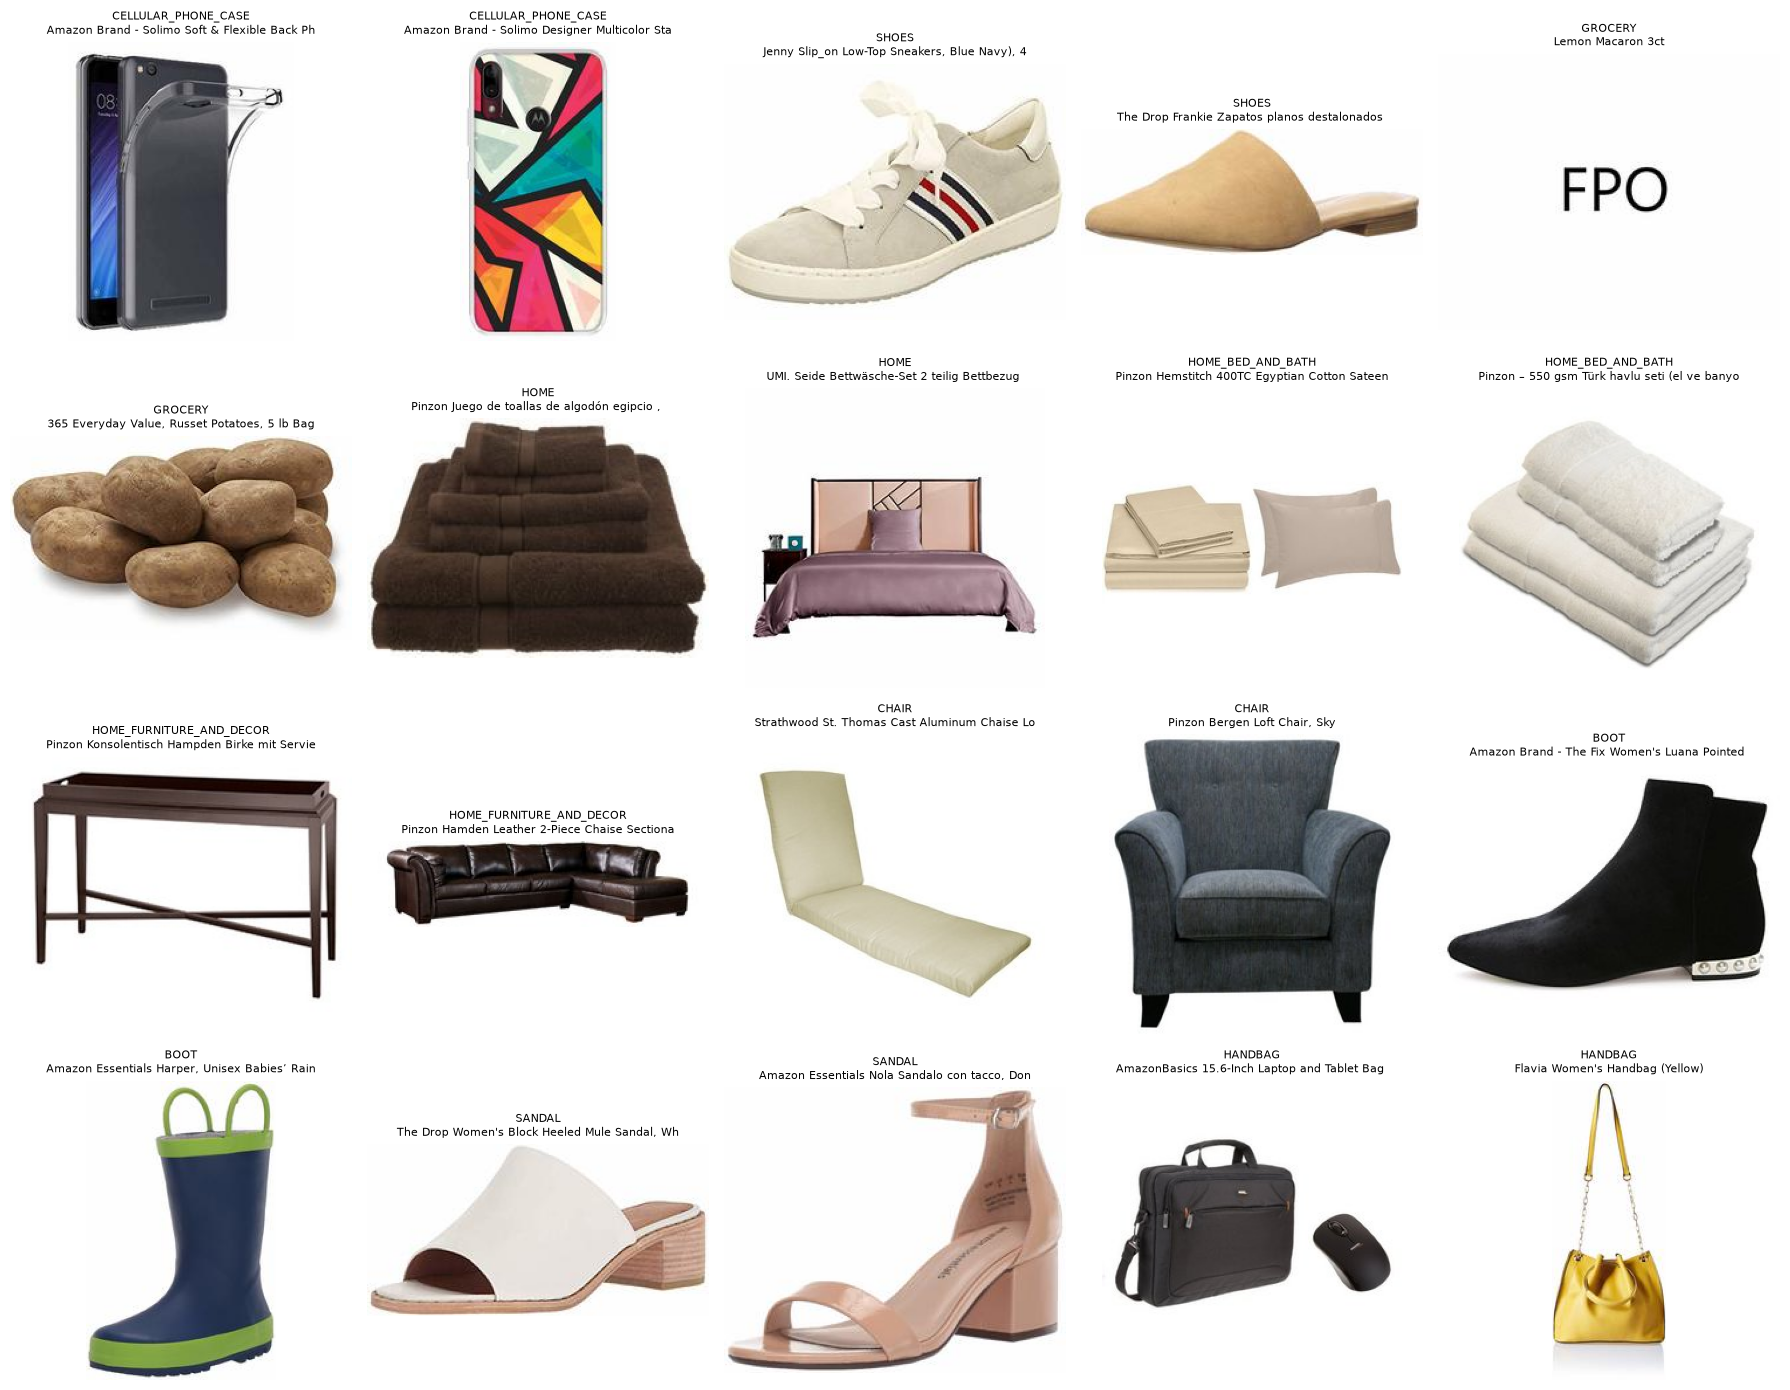

In [47]:
sample_records = subset_records[::50][:20] 

fig, axes = plt.subplots(
    4,
    5,
    figsize=(18, 14), 
)

for axis, record in zip(axes.flat, sample_records): 
    image = Image.open(record["image_path"]).convert("RGB")

    axis.imshow(image) 
    axis.set_title(
        f"{record['product_type']}\n"
        f"{record['title'][:45] if record['title'] else 'No title'}", 
        fontsize=8, 
    )
    axis.axis("off")

plt.tight_layout() 
plt.show() 

## Saving the ABO Subset Manifest

The subset manifest stores the selected image paths and product metadata.
The CLIP embedding pipeline will use this manifest as its input.

In [48]:
metadata_root = project_root / "data" / "metadata" 
metadata_root.mkdir(parents=True, exist_ok=True) 

subset_manifest_path = metadata_root / "abo_subset.csv"

print("Manifest path:", subset_manifest_path) 

Manifest path: /Users/aob/AOB/CS/Projects/clip-semantic-search/data/metadata/abo_subset.csv


In [49]:
manifest_records = [] 

for record in subset_records: 
    relative_record = record.copy() 

    relative_record["image_path"] = str(
        Path(record["image_path"]).relative_to(project_root) 
    )

    manifest_records.append(relative_record)

In [50]:
manifest_records

[{'item_id': 'B084978DK5',
  'domain_name': 'amazon.in',
  'image_id': '31Ca8NxZktL',
  'image_path': 'data/ABO/abo-images-small/images/small/12/12298343.jpg',
  'title': 'Amazon Brand - Solimo Soft & Flexible Back Phone Case for Mi Redmi 4A (Transparent) ZC',
  'product_type': 'CELLULAR_PHONE_CASE',
  'brand': 'Amazon Brand - Solimo',
  'color': 'Transparent',
  'style': 'professional'},
 {'item_id': 'B08562DD6Z',
  'domain_name': 'amazon.in',
  'image_id': '31Dzqdw8rwL',
  'image_path': 'data/ABO/abo-images-small/images/small/b6/b6637466.jpg',
  'title': 'Amazon Brand - Solimo Soft & Flexible Back Phone Case for Realme C3 (Transparent)',
  'product_type': 'CELLULAR_PHONE_CASE',
  'brand': 'Amazon Brand - Solimo',
  'color': 'Transparent',
  'style': 'professional'},
 {'item_id': 'B0093VF79G',
  'domain_name': 'amazon.com',
  'image_id': '31NJk+Ie1JL',
  'image_path': 'data/ABO/abo-images-small/images/small/04/04019b0b.jpg',
  'title': 'AmazonBasics Clear Cover Case with Screen Protec

In [51]:
manifest_fields = [
    "item_id",
    "domain_name",
    "image_id",
    "image_path",
    "title",
    "product_type",
    "brand",
    "color",
    "style",
]

In [53]:
with subset_manifest_path.open(
    mode="w", 
    newline="",
    encoding="utf-8", 
) as file: 
    writer = csv.DictWriter(
        file, 
        fieldnames=manifest_fields, 
    )

    writer.writeheader() 
    writer.writerows(manifest_records) 

print("Saved records:", len(manifest_records)) 
print("Saved to:", subset_manifest_path) 

Saved records: 1000
Saved to: /Users/aob/AOB/CS/Projects/clip-semantic-search/data/metadata/abo_subset.csv


In [55]:
with subset_manifest_path.open(
    mode='r', 
    newline="", 
    encoding='utf-8'
) as file: 
    manifest_reader = csv.DictReader(file)  
    reloaded_manifest = list(manifest_reader) 

print("Reloaded records:", len(reloaded_manifest)) 
print("First reloaded record:", reloaded_manifest[0])

Reloaded records: 1000
First reloaded record: {'item_id': 'B084978DK5', 'domain_name': 'amazon.in', 'image_id': '31Ca8NxZktL', 'image_path': 'data/ABO/abo-images-small/images/small/12/12298343.jpg', 'title': 'Amazon Brand - Solimo Soft & Flexible Back Phone Case for Mi Redmi 4A (Transparent) ZC', 'product_type': 'CELLULAR_PHONE_CASE', 'brand': 'Amazon Brand - Solimo', 'color': 'Transparent', 'style': 'professional'}


In [56]:
missing_manifest_paths = [] 

for record in reloaded_manifest: 
    image_path = project_root / record['image_path'] 

    if not image_path.is_file(): 
        missing_manifest_paths.append(str(image_path)) 

print("Missing manifest image files:", len(missing_manifest_paths))

Missing manifest image files: 0
